# Week 13 — Google Earth Engine & Cloud-Scale Time Series
## ARIA v9.0 — Student Exercise Notebook (學生練習版)

**Course (課程):** Remote Sensing and Spatial Information Analysis and Applications
**Theme (主題):** Cloud-based satellite time-series analysis with Google Earth Engine
**Study Area (研究區域):** Hualien, Taiwan (花蓮) — Post-earthquake (2024/04/03) & landslide dam (堰塞湖) analysis
**Bounding Box:** `[121.2574, 23.6546, 121.4984, 23.7447]`

---

### Learning Objectives (學習目標)
1. Access and filter large satellite archives via GEE Python API
2. Compute NDVI time series and detect vegetation change after an earthquake
3. Integrate optical (Sentinel-2) and SAR (Sentinel-1) observations
4. Create pre/post composites and compute change maps
5. Export cloud-computed products for local analysis

### How to Use This Notebook (使用說明)
- Cells marked **COMPLETE** are ready to run — do not modify them.
- Cells with `# TODO:` require you to **fill in the blanks** before running.
- `# HINT:` comments provide guidance for each exercise.
- Run cells **in order** from top to bottom.

### Prerequisites (先備知識)
- W8: NDVI fundamentals — W9: Change detection — W10: SAR basics — W12: Classification

> **Student Exercise Notebook (學生練習筆記本)** — fill in the blanks and run.

---
## S1 — Environment Setup (環境設定) ✅ COMPLETE

Install and import the required packages. We authenticate with Google Earth Engine,
set up Chinese font rendering for matplotlib, define our Area of Interest (AOI),
and run a quick connectivity test.

> **Note:** You need a GEE-enabled Google Cloud project. Replace `'your-project-id'`
> with your actual project ID.

This cell is **complete** — just run it.

In [2]:
# ============================================================
# S1 — Environment Setup (環境設定) — COMPLETE
# ============================================================
import warnings
warnings.filterwarnings('ignore')

# --- Core imports ---
import ee
import geemap
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd
from datetime import datetime, timedelta
import os, platform

# --- GEE Authentication & Initialization ---
# ee.Authenticate()  # Uncomment on first run — opens a browser auth flow
ee.Initialize(project='moonlit-mesh-479012-e0')

# --- Chinese font setup (跨平台中文字型) ---
from matplotlib import font_manager as fm

def setup_chinese_font():
    """Cross-platform Chinese font configuration."""
    system = platform.system()
    candidates = {
        'Windows': ['Microsoft JhengHei', 'Microsoft YaHei', 'SimHei'],
        'Darwin':  ['PingFang TC', 'Heiti TC', 'STHeiti'],
        'Linux':   ['Noto Sans CJK TC', 'WenQuanYi Micro Hei',
                    'AR PL UMing TW', 'Noto Sans TC']
    }
    available = {f.name for f in fm.fontManager.ttflist}
    for name in candidates.get(system, candidates['Linux']):
        if name in available:
            plt.rcParams['font.sans-serif'] = [name] + plt.rcParams['font.sans-serif']
            plt.rcParams['axes.unicode_minus'] = False
            print(f"  Chinese font set to: {name}")
            return name
    # Fallback: try all candidates
    for flist in candidates.values():
        for name in flist:
            if name in available:
                plt.rcParams['font.sans-serif'] = [name] + plt.rcParams['font.sans-serif']
                plt.rcParams['axes.unicode_minus'] = False
                print(f"  Chinese font (fallback) set to: {name}")
                return name
    print("  WARNING: No CJK font found — Chinese text may not render correctly.")
    return None

font_name = setup_chinese_font()

# --- Define AOI (定義研究區域) ---
HUALIEN_BBOX = [121.2574, 23.6546, 121.4984, 23.7447]
aoi = ee.Geometry.Rectangle(HUALIEN_BBOX)

# --- Quick connectivity test (連線測試) ---
point = ee.Geometry.Point([121.37, 23.70])
elev = ee.Image('USGS/SRTMGL1_003').sample(point, 30).first().get('elevation').getInfo()
print(f"  Connectivity OK — Elevation at test point: {elev} m")

print()
print("=" * 60)
print("  S1 COMPLETE — Environment ready")
print(f"  AOI: {HUALIEN_BBOX}")
print(f"  Platform: {platform.system()} / Python {platform.python_version()}")
print("=" * 60)

  Chinese font set to: Microsoft JhengHei
  Connectivity OK — Elevation at test point: 1009 m

  S1 COMPLETE — Environment ready
  AOI: [121.2574, 23.6546, 121.4984, 23.7447]
  Platform: Windows / Python 3.12.12


---
## S2 — Filter Sentinel-2 ImageCollection (Sentinel-2 影像集篩選) ✏️ EXERCISE

We access the **Sentinel-2 Level-2A Surface Reflectance (Harmonized)** collection
and filter it by:
- **Date range (日期範圍):** 2020-01-01 to 2026-03-31
- **Cloud cover (雲量):** less than 40%
- **Spatial bounds (空間範圍):** our Hualien AOI

### Key GEE Concepts (關鍵概念)
- `ee.ImageCollection` — a stack of images managed on the server
- `filterDate(start, end)` — keep only images within a date range
- `filterBounds(geometry)` — keep only images that overlap our AOI
- `filter(ee.Filter.lt(property, value))` — filter by metadata property

> **HINT:** See Pre-lab Step 4 for ImageCollection filtering concepts.

In [4]:
# ============================================================
# S2 — Filter Sentinel-2 ImageCollection — EXERCISE
# ============================================================

s2_col = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
          # TODO: Filter by date range — 2020-01-01 to 2026-03-31
          # HINT: .filterDate('start_date', 'end_date')
          .filterDate('2020-01-01', '2026-03-31')
          # TODO: Filter by cloud cover — keep images with CLOUDY_PIXEL_PERCENTAGE < 40
          # HINT: ee.Filter.lt('property_name', threshold_value)
          .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40))
          .filterBounds(aoi))

# --- Collection statistics (do not modify below) ---
count = s2_col.size().getInfo()
print(f"  Total Sentinel-2 images (2020-2026, cloud < 40%): {count}")

# Date range
dates = s2_col.aggregate_array('system:time_start').getInfo()
dates_dt = [datetime.utcfromtimestamp(d / 1000) for d in dates]
print(f"  Date range: {min(dates_dt).strftime('%Y-%m-%d')} -> {max(dates_dt).strftime('%Y-%m-%d')}")

# Cloud cover stats
cloud_stats = s2_col.aggregate_stats('CLOUDY_PIXEL_PERCENTAGE').getInfo()
print(f"  Cloud cover — mean: {cloud_stats['mean']:.1f}%, "
      f"min: {cloud_stats['min']:.1f}%, max: {cloud_stats['max']:.1f}%")

# --- Display first image as RGB ---
first_img = s2_col.sort('system:time_start').first()
vis_rgb = {'bands': ['B4', 'B3', 'B2'], 'min': 0, 'max': 3000}

Map2 = geemap.Map(center=[23.70, 121.40], zoom=11)
Map2.addLayer(first_img.clip(aoi), vis_rgb, 'First S2 Image (RGB)')
Map2.addLayer(aoi, {'color': 'red'}, 'AOI — Hualien')
Map2

  Total Sentinel-2 images (2020-2026, cloud < 40%): 143
  Date range: 2020-01-11 -> 2026-03-30
  Cloud cover — mean: 20.7%, min: 0.0%, max: 39.5%


Map(center=[23.7, 121.4], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

---
## S3 — NDVI Calculation + Cloud Masking (NDVI 計算與雲遮罩) ✏️ EXERCISE

Sentinel-2 Level-2A includes a **Scene Classification Layer (SCL)** band.
We use SCL to mask clouds, cloud shadows, snow, and other unwanted pixels.

| SCL Value | Class             | Keep? |
|-----------|-------------------|-------|
| 4         | Vegetation        | Yes   |
| 5         | Bare soil         | Yes   |
| 6         | Water             | Yes   |
| 7         | Unclassified      | Yes   |
| 3, 8, 9, 10, 11 | Cloud/shadow/snow | No |

**NDVI = (NIR - Red) / (NIR + Red) = (B8 - B4) / (B8 + B4)**

> **HINT:** B8 = NIR, B4 = Red — same as W8. The `normalizedDifference` function
> takes `['NIR_band', 'Red_band']` in that order.

In [ ]:
# ============================================================
# S3 — NDVI Calculation + Cloud Masking — EXERCISE
# ============================================================

def mask_and_ndvi(image):
    """Apply SCL cloud mask and compute NDVI for a single S2 image."""
    scl = image.select('SCL')

    # TODO: Create a mask that keeps good pixels (vegetation=4, bare soil=5, water=6, unclassified=7)
    # HINT: Use scl.eq(value) and chain with .Or()
    # Example pattern: scl.eq(4).Or(scl.eq(5)).Or(...)
    good_mask = (scl.eq(4).Or(scl.eq(5)).Or(scl.eq(6)).Or(scl.eq(7)))

    # TODO: Compute NDVI using normalizedDifference
    # HINT: normalizedDifference takes ['NIR_band_name', 'Red_band_name']
    # For Sentinel-2: NIR = B8, Red = B4
    ndvi = image.normalizedDifference(['B8', 'B4']).rename('NDVI')

    return (image.addBands(ndvi)
            .updateMask(good_mask)
            .copyProperties(image, ['system:time_start']))

# Apply to entire collection
ndvi_col = s2_col.map(mask_and_ndvi)

# --- Display a sample NDVI image (do not modify below) ---
sample_img = ndvi_col.sort('system:time_start').first()
vis_ndvi = {'bands': ['NDVI'], 'min': 0, 'max': 0.8,
            'palette': ['red', 'yellow', 'green', 'darkgreen']}

Map3 = geemap.Map(center=[23.70, 121.40], zoom=11)
Map3.addLayer(sample_img.select('NDVI').clip(aoi), vis_ndvi, 'Sample NDVI')
Map3.addLayer(aoi, {'color': 'red'}, 'AOI')
Map3

Map(center=[23.7, 121.4], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

---
## S4 — Monthly NDVI Time Series with Spatial Spread (月均 NDVI 時間序列 + 空間分布) ✏️ EXERCISE

We aggregate NDVI to monthly medians, then retrieve **three spatial statistics**
over our AOI: the **mean** (regional average), **min** (worst pixel), and
**max** (best pixel).

### Why Three Lines Instead of One? (為什麼需要三條線？)

Imagine a classroom of 30 students taking an exam. If the class average is 75,
you might think "the class did OK." But what if the range is 20 to 100?
That tells a very different story — some students excelled, others struggled.

The same logic applies to satellite pixels:
- **Mean** = class average (overall health of the region)
- **Min** = lowest-scoring student (worst-damaged pixel — a landslide scar?)
- **Max** = top student (healthiest forest pixel — undamaged reference)

**Your tasks:**
1. Run the provided function to compute monthly mean/min/max
2. Create the matplotlib time series plot with a **shaded band** between min and max
3. Add the earthquake marker on 2024-04-03
4. Answer the guided scientific inquiry questions below

> The earthquake struck on **2024-04-03** — does the min value reveal damage
> signals that the mean alone might miss?


In [6]:
# ============================================================
# S4 — Monthly NDVI Time Series with Spatial Spread — PARTIALLY COMPLETE
# ============================================================

# --- This function is COMPLETE — do not modify ---
def compute_monthly_ndvi(ndvi_collection, aoi, start_year=2020, end_year=2026):
    """Compute monthly NDVI statistics (mean, min, max) over an AOI.
    Returns a list of (date, mean, min, max) tuples.
    """
    results = []

    for year in range(start_year, end_year + 1):
        for month in range(1, 13):
            start = f'{year}-{month:02d}-01'
            if month == 12:
                end = f'{year + 1}-01-01'
            else:
                end = f'{year}-{month + 1:02d}-01'

            monthly = ndvi_collection.filterDate(start, end).select('NDVI')
            n = monthly.size().getInfo()

            if n == 0:
                results.append((datetime(year, month, 15), None, None, None))
                continue

            median_img = monthly.median()
            stats = median_img.reduceRegion(
                reducer=ee.Reducer.mean()
                    .combine(ee.Reducer.min(), sharedInputs=True)
                    .combine(ee.Reducer.max(), sharedInputs=True),
                geometry=aoi,
                scale=100,
                maxPixels=1e8
            ).getInfo()

            v_mean = stats.get('NDVI_mean')
            v_min  = stats.get('NDVI_min')
            v_max  = stats.get('NDVI_max')
            results.append((datetime(year, month, 15), v_mean, v_min, v_max))

            if v_mean is not None:
                print(f'  {start[:7]}: mean={v_mean:.3f}  min={v_min:.3f}  '
                      f'max={v_max:.3f}  (n={n})')
            else:
                print(f'  {start[:7]}: no data  (n={n})')

    return results

print('Computing monthly NDVI with spatial statistics...')
print('(mean = regional average, min = worst pixel, max = best pixel)')
print()
monthly_data = compute_monthly_ndvi(ndvi_col, aoi)

# --- Prepare data for plotting (do not modify) ---
dates_plot  = [d for d, m, mn, mx in monthly_data if m is not None]
mean_plot   = [m for d, m, mn, mx in monthly_data if m is not None]
min_plot    = [mn for d, m, mn, mx in monthly_data if m is not None]
max_plot    = [mx for d, m, mn, mx in monthly_data if m is not None]


Computing monthly NDVI with spatial statistics...
(mean = regional average, min = worst pixel, max = best pixel)

  2020-01: mean=0.706  min=-0.355  max=0.997  (n=3)
  2020-02: mean=0.695  min=-0.231  max=0.922  (n=2)
  2020-03: mean=0.630  min=-0.041  max=0.895  (n=1)
  2020-04: mean=0.659  min=-0.070  max=0.900  (n=1)
  2020-05: mean=0.639  min=-0.112  max=0.951  (n=2)
  2020-06: mean=0.752  min=-0.159  max=0.955  (n=3)
  2020-07: mean=0.709  min=-0.069  max=0.941  (n=2)
  2020-08: mean=0.716  min=-0.100  max=0.940  (n=2)
  2020-09: mean=0.635  min=-0.057  max=0.926  (n=2)
  2020-10: mean=0.698  min=-0.131  max=0.933  (n=2)
  2020-11: mean=0.755  min=-0.229  max=0.954  (n=3)
  2020-12: mean=0.698  min=-0.133  max=0.935  (n=1)
  2021-01: mean=0.711  min=-0.149  max=0.996  (n=3)
  2021-02: mean=0.625  min=-0.081  max=0.891  (n=3)
  2021-03: mean=0.692  min=-0.094  max=0.921  (n=3)
  2021-04: mean=0.724  min=-0.129  max=0.964  (n=2)
  2021-05: mean=0.716  min=-0.115  max=0.993  (n=3)
  

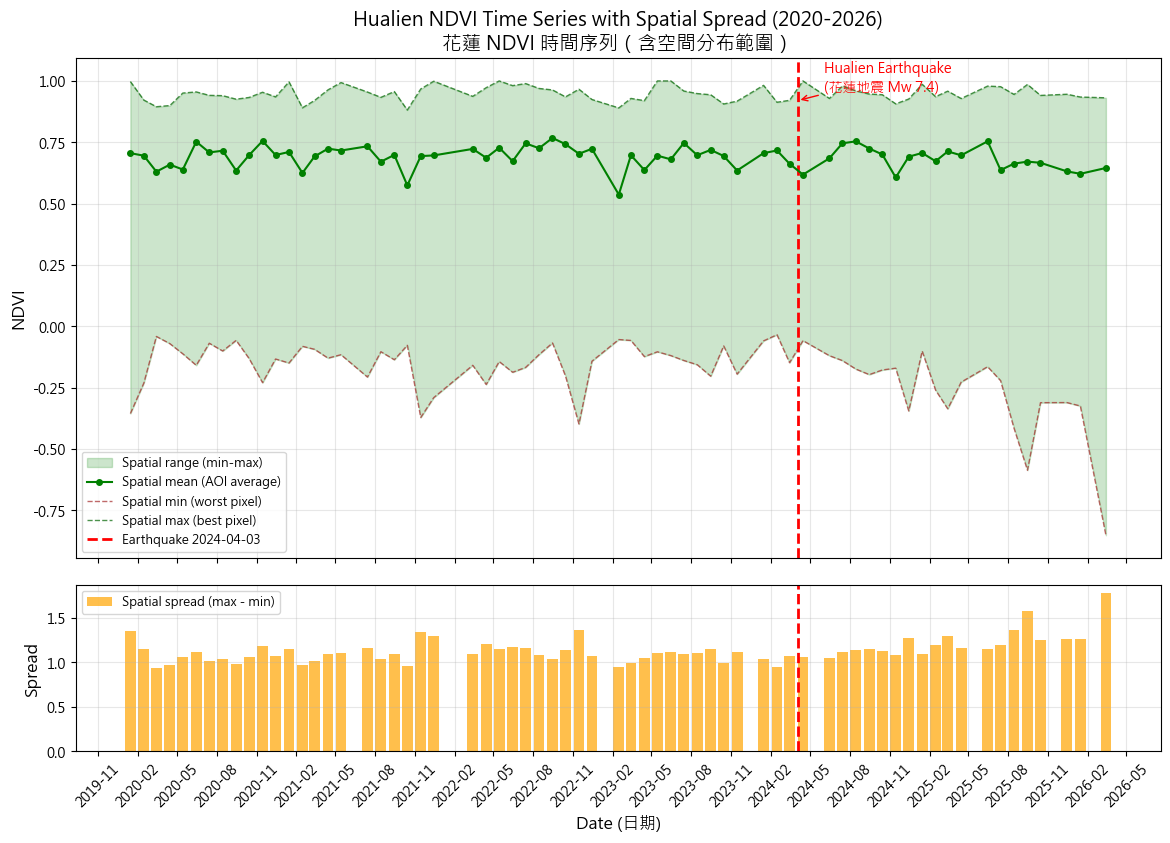

  Pre-earthquake  avg spread: 1.0936
  Post-earthquake avg spread: 1.2264


In [7]:
# ============================================================
# S4 (continued) — Plot NDVI Time Series with Spread — EXERCISE
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(14, 9), height_ratios=[3, 1],
                         sharex=True, gridspec_kw={'hspace': 0.08})

# --- Upper panel: NDVI time series with min-max band ---
ax = axes[0]

# TODO: Add a shaded band between min_plot and max_plot
# HINT: ax.fill_between(x, y_low, y_high, alpha=0.2, color='green',
#                       label='Spatial range (min-max)')
ax.fill_between(dates_plot, min_plot, max_plot,
                alpha=0.2, color='green', label='Spatial range (min-max)')

# Plot mean, min, max lines (complete)
ax.plot(dates_plot, mean_plot, 'o-', color='green', markersize=4, linewidth=1.5,
        label='Spatial mean (AOI average)', zorder=3)
ax.plot(dates_plot, min_plot, '--', color='brown', linewidth=1, alpha=0.7,
        label='Spatial min (worst pixel)')
ax.plot(dates_plot, max_plot, '--', color='darkgreen', linewidth=1, alpha=0.7,
        label='Spatial max (best pixel)')

# TODO: Add the earthquake marker as a vertical dashed red line
# HINT: datetime(2024, 4, 3)
eq_date = datetime(2024, 4, 3)
ax.axvline(eq_date, color='red', linestyle='--', linewidth=2,
           label='Earthquake 2024-04-03')
ax.annotate('Hualien Earthquake\n(花蓮地震 Mw 7.4)',
            xy=(eq_date, max(max_plot) * 0.92),
            xytext=(eq_date + timedelta(days=60), max(max_plot) * 0.96),
            fontsize=10, color='red',
            arrowprops=dict(arrowstyle='->', color='red'))

ax.set_ylabel('NDVI', fontsize=12)
ax.set_title('Hualien NDVI Time Series with Spatial Spread (2020-2026)\n'
             '花蓮 NDVI 時間序列（含空間分布範圍）', fontsize=14)
ax.legend(loc='lower left', fontsize=9)
ax.grid(True, alpha=0.3)

# --- Lower panel: Spread (max - min) ---
ax2 = axes[1]
spread_plot = [mx - mn for mn, mx in zip(min_plot, max_plot)]
ax2.bar(dates_plot, spread_plot, width=25, color='orange', alpha=0.7,
        label='Spatial spread (max - min)')
ax2.axvline(eq_date, color='red', linestyle='--', linewidth=2)
ax2.set_ylabel('Spread', fontsize=12)
ax2.set_xlabel('Date (日期)', fontsize=12)
ax2.legend(loc='upper left', fontsize=9)
ax2.grid(True, alpha=0.3)
ax2.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Summary statistics ---
pre_spreads = [mx - mn for d, m, mn, mx in monthly_data
               if m is not None and d < eq_date]
post_spreads = [mx - mn for d, m, mn, mx in monthly_data
                if m is not None and d >= eq_date]
if pre_spreads and post_spreads:
    print(f'  Pre-earthquake  avg spread: {sum(pre_spreads)/len(pre_spreads):.4f}')
    print(f'  Post-earthquake avg spread: {sum(post_spreads)/len(post_spreads):.4f}')


### S4 — Scientific Inquiry: From Data to Discovery (科學探究：從數據到發現)

Good scientists don't just plot data — they **question what the data is telling them**.
Answer these questions based on your three-line plot above.

---

**Q1: Observe (觀察) — Describe the three lines:**
- Does the mean (green) show a clear earthquake signal? Why or why not?
- Does the min (brown) show a different story? What happens to it after 2024-04?
- Does the max (dark green) change much after the earthquake?

> *Your answer:*

---

**Q2: Question (質疑方法論) — Why does the mean miss the signal?**

Our AOI is approximately 24 km x 10 km. If earthquake landslides cover
5 km^2 of this area, what percentage of pixels are damaged? Would the
mean NDVI shift noticeably? What does this tell you about choosing the
**right spatial scale** for analysis?

> *Your answer:*

---

**Q3: Interpret the spread (解讀展幅) — Look at the orange bar chart:**
- Did the spread (max - min) change after the earthquake?
- What does an increase in spread mean physically? (Think: what happens to a
  landscape when some areas collapse into landslides while nearby forests are fine?)

> *Your answer:*

---

**Q4: Design the next experiment (設計下一步實驗):**

If you wanted to find **exactly where** the worst-damaged pixels are,
what would you do next? (Hint: think about what D5 does, or how you might
use a smaller AOI focused on known landslide areas.)

> *Your answer:*

---

**Q5: Connect to the real world (連結真實世界):**

Imagine you work for the Soil and Water Conservation Bureau (水土保持局).
After a major earthquake, you need to quickly identify which mountain roads
and villages are at risk from landslides. Based on what you've learned:
- Would you use mean NDVI or min NDVI to prioritize rescue efforts? Why?
- How would you combine optical (NDVI) and SAR data for a cloudy area like Hualien?
- What other data would you want? (Elevation? Slope? Population density?)

> *Your answer:*

---

> **The scientific process (科學方法):**
> Observe anomaly → Question methodology → Refine analysis → Form hypothesis → Test it
>
> This is exactly what we just did: the mean looked "fine" → we questioned whether
> averaging was appropriate → we added min/max → we saw the real damage signal → 
> now D5 will map exactly where the damage occurred.


---
## S4b — Scale Test: Taroko Gorge vs Broad Hualien (尺度測試：太魯閣 vs 寬幅花蓮) ✏️ EXERCISE

You just analyzed NDVI across a broad AOI (~240 km^2) that includes flatlands,
wetlands, and mountains. But the 2024 earthquake damage was concentrated in the
**Taroko Gorge** — steep mountain slopes where landslides buried roads and trails.

**Hypothesis:** If we focus on the damage zone, the NDVI drop will be much clearer.

**Your task:** Run the same `compute_monthly_ndvi` function on a smaller,
focused AOI and compare the results side-by-side.

| AOI | Area | What's Inside |
|-----|------|---------------|
| Broad Hualien | ~240 km^2 | Plains, wetlands, city, mountains |
| Taroko Focus | ~1,040 km² | Taroko Gorge, Suhua Hwy, mountain slopes |


In [ ]:
# ============================================================
# S4b — Taroko Gorge Focused Analysis — EXERCISE
# ============================================================

# TODO: Define the Taroko focused AOI
# This covers the steep gorge area where landslides were most severe
# HINT: The coordinates are [west, south, east, north]
TAROKO_BBOX = [121.34526379253053, 24.046021742135874, 121.85149217685861, 24.35767637905926]
aoi_taroko = ee.Geometry.Rectangle(TAROKO_BBOX)

# --- Compute monthly NDVI for Taroko (reuse the same function) ---
print('Computing monthly NDVI for Taroko Gorge focused AOI...')
print(f'Taroko BBOX: {TAROKO_BBOX}')
print()
taroko_data = compute_monthly_ndvi(ndvi_col, aoi_taroko)

# --- Prepare Taroko data ---
t_dates = [d for d, m, mn, mx in taroko_data if m is not None]
t_mean  = [m for d, m, mn, mx in taroko_data if m is not None]
t_min   = [mn for d, m, mn, mx in taroko_data if m is not None]
t_max   = [mx for d, m, mn, mx in taroko_data if m is not None]

# ============================================================
# Side-by-side comparison
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(16, 10),
                         height_ratios=[3, 1],
                         sharex=True,
                         gridspec_kw={'hspace': 0.08, 'wspace': 0.25})

eq_date = datetime(2024, 4, 3)

for col, (title, dates, means, mins, maxs, desc) in enumerate([
    ('Broad Hualien AOI (~240 km\u00b2)',
     dates_plot, mean_plot, min_plot, max_plot,
     'Mixed terrain: plains + wetlands + mountains'),
    ('Taroko Gorge Focus (~1,040 km²)',
     t_dates, t_mean, t_min, t_max,
     'Taroko Gorge to Suhua Hwy mountain corridor'),
]):
    ax = axes[0, col]

    # TODO: Add the shaded band between min and max
    # HINT: Same as S4 — ax.fill_between(dates, mins, maxs, ...)
    ax.fill_between(dates, ____, ____,
                    alpha=0.2, color='green', label='Range (min-max)')

    ax.plot(dates, means, 'o-', color='green', markersize=3,
            linewidth=1.5, label='Mean', zorder=3)
    ax.plot(dates, mins, '--', color='brown', linewidth=1,
            alpha=0.7, label='Min (worst pixel)')
    ax.plot(dates, maxs, '--', color='darkgreen', linewidth=1,
            alpha=0.7, label='Max (best pixel)')
    ax.axvline(eq_date, color='red', linestyle='--', linewidth=2)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_ylabel('NDVI' if col == 0 else '')
    ax.legend(fontsize=8, loc='lower left')
    ax.grid(True, alpha=0.3)
    ax.text(0.5, -0.02, desc, transform=ax.transAxes,
            ha='center', fontsize=10, color='gray', style='italic')
    ax.set_ylim(-0.5, 1.05)

    ax2 = axes[1, col]
    spreads = [mx - mn for mn, mx in zip(mins, maxs)]
    ax2.bar(dates, spreads, width=25, color='orange', alpha=0.7)
    ax2.axvline(eq_date, color='red', linestyle='--', linewidth=2)
    ax2.set_ylabel('Spread' if col == 0 else '')
    ax2.grid(True, alpha=0.3)

for ax in axes[1, :]:
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=6))
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
    ax.set_xlabel('Date (日期)')

fig.suptitle('Scale Matters: Broad AOI vs Taroko Focus\n'
             '尺度效應：寬幅 AOI vs 太魯閣聚焦', fontsize=15, y=1.01)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# --- Summary stats ---
for label, data in [('Broad Hualien', monthly_data), ('Taroko Focus', taroko_data)]:
    pre  = [(d, m, mn, mx) for d, m, mn, mx in data
            if m is not None and d < eq_date]
    post = [(d, m, mn, mx) for d, m, mn, mx in data
            if m is not None and d >= eq_date]
    if pre and post:
        pre_mean = sum(m for _, m, _, _ in pre) / len(pre)
        post_mean = sum(m for _, m, _, _ in post) / len(post)
        pre_min_avg = sum(mn for _, _, mn, _ in pre) / len(pre)
        post_min_avg = sum(mn for _, _, mn, _ in post) / len(post)
        print(f'\n  {label}:')
        print(f'    Mean  — pre: {pre_mean:.4f}  post: {post_mean:.4f}  '
              f'change: {post_mean-pre_mean:+.4f}')
        print(f'    Min   — pre: {pre_min_avg:.4f}  post: {post_min_avg:.4f}  '
              f'change: {post_min_avg-pre_min_avg:+.4f}')


### S4b — Your Analysis (你的分析)

**Q1: Compare the two panels.** Which AOI shows a clearer earthquake damage signal?
Look at the mean line, the min line, and the spread — which changed more dramatically
in the Taroko focus?

> *Your answer:*

**Q2: Why does scale matter?** If a government agency analyzed the entire Hualien
county and concluded "vegetation impact was minimal," would that be accurate?
What would you recommend they do differently?

> *Your answer:*

**Q3: Hierarchical analysis.** Real disaster monitoring uses three levels:
1. Broad scan (country/county) → detect anomalies
2. Focused zoom (valley/slope) → pinpoint damage
3. Pixel-level mapping → individual landslide scars

You just performed levels 1 and 2. Which section of this notebook performs level 3?

> *Your answer:*

> **Key takeaway:** The same satellite data, analyzed at different spatial scales,
> tells fundamentally different stories. Choosing the right scale is as important
> as choosing the right algorithm.


---
## S5 — Three-Phase Composite Comparison (三期中值合成比較) ✏️ EXERCISE

The 2024 earthquake triggered landslides that created **landslide dams** (堰塞湖),
including the Mataian landslide dam (馬太鞍堰塞湖). To track this multi-event
disaster timeline, we compare three periods:

| Phase | Period | What Happened |
|-------|--------|---------------|
| **Phase 1** | 2023/01 – 2024/03 | Pre-earthquake baseline |
| **Phase 2** | 2024/04 – 2024/09 | Post-earthquake: landslides, road collapse |
| **Phase 3** | 2025/10 – 2026/03 | Post-landslide-dam: breach aftermath |

> **HINT:** Use `.filterDate('start', 'end').select('NDVI').median()` for each phase.


In [ ]:
# ============================================================
# S5 — Three-Phase Composite Comparison — EXERCISE
# ============================================================

# TODO: Create Phase 1 — pre-earthquake NDVI composite
# HINT: filterDate('2023-01-01', '2024-03-31'), select('NDVI'), .median()
pre_ndvi = (ndvi_col
            .filterDate('2023-01-01', '2024-03-31')
            .select('NDVI')
            .median())

# TODO: Create Phase 2 — post-earthquake NDVI composite
# HINT: filterDate('2024-04-01', '2024-09-30')
post_eq_ndvi = (ndvi_col
                .filterDate('2024-04-01', '2024-09-30')
                .select('NDVI')
                .median())

# TODO: Create Phase 3 — post-landslide-dam NDVI composite
# HINT: filterDate('2025-10-01', '2026-03-31')
post_dam_ndvi = (ndvi_col
                 .filterDate('2025-10-01', '2026-03-31')
                 .select('NDVI')
                 .median())

# TODO: Compute change maps
# HINT: .subtract() and .rename()
delta_eq    = post_eq_ndvi.subtract(pre_ndvi).rename('delta_NDVI')
delta_dam   = post_dam_ndvi.subtract(post_eq_ndvi).rename('delta_NDVI_dam')
delta_total = post_dam_ndvi.subtract(pre_ndvi).rename('delta_NDVI_total')

# --- Visualization (provided — do not modify below) ---
vis_ndvi  = {'min': 0, 'max': 0.8,
             'palette': ['red', 'yellow', 'green', 'darkgreen']}
vis_delta = {'min': -0.3, 'max': 0.3,
             'palette': ['red', 'white', 'blue']}

Map5 = geemap.Map(center=[23.70, 121.40], zoom=11)
Map5.addLayer(pre_ndvi.clip(aoi), vis_ndvi, 'Phase 1: Pre-EQ')
Map5.addLayer(post_eq_ndvi.clip(aoi), vis_ndvi, 'Phase 2: Post-EQ')
Map5.addLayer(post_dam_ndvi.clip(aoi), vis_ndvi, 'Phase 3: Post-Dam')
Map5.addLayer(delta_eq.clip(aoi), vis_delta, 'ΔNDVI: EQ damage (P2-P1)')
Map5.addLayer(delta_dam.clip(aoi), vis_delta, 'ΔNDVI: Dam change (P3-P2)')
Map5.addLayer(delta_total.clip(aoi), vis_delta, 'ΔNDVI: Total (P3-P1)')
Map5.addLayer(aoi, {'color': 'yellow'}, 'AOI')
Map5


### S5 Visual — 三期衛星影像對比 ✏️ EXERCISE

用 geemap 在互動地圖上展示三期的 RGB 真色合成和 NDVI 合成。

**觀察任務：**
1. 在 RGB 地圖上，找到太魯閣峽谷附近最明顯的崩塌區（Phase 1 綠 → Phase 2 灰白）
2. 在 ΔNDVI 地圖上，比較三張差值圖的紅色（損失）和綠色（恢復）分佈
3. 堰塞湖潰堤後是否造成新損害？還是已有部分恢復？

In [ ]:
# ============================================================
# S5 Visual — Three-Phase Map Comparison — EXERCISE
# ============================================================

# TODO: Build cloud-masked S2 RGB composites for three phases
s2_masked = s2_col.map(lambda img: img.updateMask(
    img.select('SCL').eq(4).Or(img.select('SCL').eq(5))
    .Or(img.select('SCL').eq(6)).Or(img.select('SCL').eq(7))
))

rgb_pre = s2_masked.filterDate('2023-01-01', '2024-03-31').median().select(['B4','B3','B2'])
rgb_post_eq = s2_masked.filterDate('2024-04-01', '2024-09-30').median().select(['B4','B3','B2'])  # TODO: fill dates
rgb_post_dam = s2_masked.filterDate('2025-10-01', '2026-03-31').median().select(['B4','B3','B2'])  # TODO: fill dates

rgb_vis = {'min': 0, 'max': 3000}
ndvi_vis = {'min': 0, 'max': 0.8, 'palette': ['brown', 'yellow', 'green', 'darkgreen']}
delta_vis = {'min': -0.3, 'max': 0.3, 'palette': ['red', 'orange', 'white', 'lightgreen', 'darkgreen']}

# === Map 1: RGB True Color ===
Map1 = geemap.Map(center=[24.20, 121.60], zoom=11)
Map1.addLayer(rgb_pre, rgb_vis, 'Phase 1: Pre-EQ RGB')
Map1.addLayer(rgb_post_eq, rgb_vis, 'Phase 2: Post-EQ RGB')
Map1.addLayer(rgb_post_dam, rgb_vis, 'Phase 3: Post-Dam RGB')
Map1.addLayerControl()
Map1


In [ ]:
# === Map 2: NDVI + Delta Maps ===
# TODO: Create a geemap Map and add the six layers:
#   - pre_ndvi, post_eq_ndvi, post_dam_ndvi (NDVI composites)
#   - delta_eq, delta_dam, delta_total (difference maps)

Map2 = geemap.Map(center=[24.20, 121.60], zoom=11)
# TODO: Add your layers here using Map2.addLayer(...)
#   HINT: use ndvi_vis for NDVI layers, delta_vis for difference layers
#   HINT: use shown=False for layers you don't want visible by default

Map2.addLayerControl()
Map2


**✏️ 觀察紀錄：**

1. 地震直接損害（delta_eq 紅色區）主要集中在哪些地形？（峽谷？稜線？河谷？）

   你的觀察：___

2. 堰塞湖潰堤後（delta_dam），是出現新損害還是植被恢復？分佈在哪裡？

   你的觀察：___

3. 如果你是水土保持局工程師，這三張 ΔNDVI 地圖分別幫你做什麼決策？

   你的想法：___

In [ ]:
# --- Three-phase statistics (do not modify) ---
for label, delta_img, band_name in [
    ('EQ damage (Phase 2 - Phase 1)',    delta_eq,    'delta_NDVI'),
    ('Dam change (Phase 3 - Phase 2)',   delta_dam,   'delta_NDVI_dam'),
    ('Total change (Phase 3 - Phase 1)', delta_total, 'delta_NDVI_total'),
]:
    stats = delta_img.reduceRegion(
        reducer=ee.Reducer.mean()
            .combine(ee.Reducer.stdDev(), sharedInputs=True),
        geometry=aoi, scale=100, maxPixels=1e8
    ).getInfo()
    mean_v = stats.get(f'{band_name}_mean')
    std_v  = stats.get(f'{band_name}_stdDev')
    damage = delta_img.lt(-0.15)
    area = damage.multiply(ee.Image.pixelArea()).reduceRegion(
        reducer=ee.Reducer.sum(), geometry=aoi,
        scale=100, maxPixels=1e8
    ).getInfo()
    area_km2 = (area.get(band_name, 0) or 0) / 1e6
    print(f'\n  {label}:')
    if mean_v: print(f'    Mean ΔNDVI:  {mean_v:+.4f}')
    if std_v:  print(f'    StdDev:      {std_v:.4f}')
    print(f'    Damaged area (ΔNDVI < -0.15): {area_km2:.2f} km2')

# Keep reference for S7
delta_ndvi = delta_eq


---
## S6 — Sentinel-1 SAR GRD Time Series (Sentinel-1 SAR 時間序列) ✏️ EXERCISE

Synthetic Aperture Radar (SAR) is **cloud-independent** — it penetrates clouds and
works day/night. This is critical for Hualien, which has frequent cloud cover.

We use **Sentinel-1 GRD** (Ground Range Detected) data:
- **IW mode** (Interferometric Wide swath) — standard land observation mode
- **VV polarization** — sensitive to surface roughness changes
- Values are in **decibels (dB)** — logarithmic scale

> **HINT:** The instrument mode is called `'IW'` and we want the `'VV'` band.

In [ ]:
# ============================================================
# S6 — Sentinel-1 SAR GRD Time Series — EXERCISE
# ============================================================

s1_col = (ee.ImageCollection('COPERNICUS/S1_GRD')
          .filterDate('2022-01-01', '2026-03-31')
          # TODO: Filter by instrument mode — should be 'IW'
          # HINT: ee.Filter.eq('instrumentMode', 'mode_name')
          .filter(ee.Filter.eq('instrumentMode', 'IW'))
          .filter(ee.Filter.eq('orbitProperties_pass', 'DESCENDING'))
          .filter(ee.Filter.listContains('transmitterReceiverPolarisation', 'VV'))
          .filterBounds(aoi)
          # TODO: Select the VV band
          # HINT: .select('band_name')
          .select('VV'))

s1_count = s1_col.size().getInfo()
print(f"  Sentinel-1 GRD images (2022-2026, DESC, VV): {s1_count}")

In [ ]:
# ============================================================
# S6 (continued) — SAR Time Series Extraction & Plot — COMPLETE
# ============================================================

# --- Compute mean VV per image over AOI (complete) ---
def get_vv_stats(image):
    """Extract mean VV over AOI for a single image."""
    stats = image.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=100,
        maxPixels=1e8
    )
    return image.set('mean_VV', stats.get('VV'))

s1_with_stats = s1_col.map(get_vv_stats)

# Retrieve client-side
s1_info = s1_with_stats.aggregate_array('system:time_start').getInfo()
s1_vv = s1_with_stats.aggregate_array('mean_VV').getInfo()

s1_dates = [datetime.utcfromtimestamp(t / 1000) for t in s1_info]
s1_values = [v for v in s1_vv]

# Filter out None values
valid = [(d, v) for d, v in zip(s1_dates, s1_values) if v is not None]
s1_dates_clean = [d for d, v in valid]
s1_values_clean = [v for d, v in valid]

print(f"  Valid observations: {len(s1_dates_clean)}")

# --- Plot ---
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(s1_dates_clean, s1_values_clean, '.', color='navy', markersize=3, alpha=0.6,
        label='Mean VV (dB)')

# Rolling average
df_s1 = pd.DataFrame({'date': s1_dates_clean, 'VV': s1_values_clean})
df_s1 = df_s1.sort_values('date')
df_s1['VV_smooth'] = df_s1['VV'].rolling(window=5, center=True).mean()
ax.plot(df_s1['date'], df_s1['VV_smooth'], '-', color='dodgerblue', linewidth=2,
        label='5-image rolling mean')

# TODO: Add the earthquake marker — same as S4
# HINT: ax.axvline(datetime(2024, 4, 3), color='red', linestyle='--', linewidth=2)
# ---- YOUR CODE HERE ----


ax.set_xlabel('Date (日期)', fontsize=12)
ax.set_ylabel('Mean VV Backscatter (dB)', fontsize=12)
ax.set_title('Hualien SAR VV Time Series (2022-2026)\n花蓮 SAR VV 時間序列', fontsize=14)
ax.legend(loc='lower left')
ax.grid(True, alpha=0.3)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### S6 — Your Observations (你的觀察)

**TODO:** After running the SAR time series plot, write 2-3 observations:

1. *(How does SAR data availability compare to optical (Sentinel-2)?)*
2. *(Do you see any change around the earthquake date?)*
3. *(Why is SAR particularly useful for monitoring Hualien?)*

---
## S7 — SAR Pre/Post Composite + Cross-Reference (SAR 震前震後 + 交叉比對) ✏️ EXERCISE

Similar to S5, create pre/post median composites from SAR data and compute
the difference (Delta-VV). Then cross-reference with Delta-NDVI to identify areas
where **both** optical and SAR sensors detect damage.

**High-confidence damage = areas where BOTH sensors agree:**
- Delta-NDVI < -0.15 (vegetation loss detected by optical)
- |Delta-VV| > 2 dB (backscatter change detected by SAR)

> **HINT:** Follow the same pattern as S5: filterDate -> median -> subtract.

In [ ]:
# ============================================================
# S7 — SAR Pre/Post Composite + Cross-Reference — EXERCISE
# ============================================================

# TODO: Create pre-earthquake VV composite (same date range as S5)
# HINT: s1_col.filterDate('2023-01-01', '2024-03-31').median()
pre_vv = (s1_col
          .filterDate('2023-01-01', '2024-03-31 ')
          .median())

# TODO: Create post-earthquake VV composite
# HINT: s1_col.filterDate('2024-04-01', '2026-03-31').median()
post_vv = (s1_col
           .filterDate('2024-04-01', '2026-03-31')
           .median())

# TODO: Compute delta_VV = post - pre
delta_vv = post_vv.subtract(pre_vv).rename('delta_VV')

# --- Visualization (provided) ---
vis_vv = {'min': -20, 'max': -5, 'palette': ['black', 'white']}
vis_dvv = {'min': -4, 'max': 4, 'palette': ['blue', 'white', 'red']}

Map7 = geemap.Map(center=[23.70, 121.40], zoom=11)
Map7.addLayer(pre_vv.clip(aoi), vis_vv, 'Pre-EQ VV (震前)')
Map7.addLayer(post_vv.clip(aoi), vis_vv, 'Post-EQ VV (震後)')
Map7.addLayer(delta_vv.clip(aoi), vis_dvv, 'Delta-VV (Post - Pre)')
Map7.addLayer(aoi, {'color': 'yellow'}, 'AOI')
Map7

In [ ]:
# ============================================================
# S7 (continued) — Cross-Reference Analysis — EXERCISE
# ============================================================

# TODO: Create a mask where BOTH conditions are true:
# 1. delta_NDVI < -0.15 (vegetation loss)
# 2. abs(delta_VV) > 2 (SAR backscatter change > 2 dB)
#
# HINT: For condition 1, use delta_ndvi.lt(-0.15)
# HINT: For condition 2, use delta_vv.abs().gt(2)
# HINT: Combine with .And() and then .selfMask()

ndvi_damage = delta_ndvi.lt(-0.15)
vv_damage = delta_vv.abs().gt(2)
sar_damage = ndvi_damage.And(vv_damage)
high_confidence = sar_damage.selfMask()

# --- Visualization (provided) ---
vis_delta = {'min': -0.3, 'max': 0.3, 'palette': ['red', 'white', 'blue']}

Map7b = geemap.Map(center=[23.70, 121.40], zoom=11)
Map7b.addLayer(delta_ndvi.clip(aoi), vis_delta, 'Delta-NDVI')
Map7b.addLayer(delta_vv.clip(aoi), vis_dvv, 'Delta-VV')
Map7b.addLayer(high_confidence.clip(aoi),
               {'palette': ['magenta'], 'min': 0, 'max': 1},
               'High-Confidence Damage (Delta-NDVI<-0.15 & |Delta-VV|>2dB)')
Map7b.addLayer(aoi, {'color': 'yellow'}, 'AOI')
Map7b

In [ ]:
# --- Damage area statistics (do not modify) ---
combined_area = high_confidence.multiply(ee.Image.pixelArea()).reduceRegion(
    reducer=ee.Reducer.sum(),
    geometry=aoi,
    scale=100,
    maxPixels=1e8
).getInfo()

# The band name depends on which image was used in .And()
# Try both possible band names
combined_km2 = 0
for key in combined_area:
    if combined_area[key] is not None:
        combined_km2 = combined_area[key] / 1e6
        break

print("Cross-sensor Damage Detection (跨感測器損害偵測):")
print(f"  Area detected by BOTH sensors: {combined_km2:.2f} km2")
print()
print("  Multi-sensor fusion provides higher confidence in damage assessment.")
print("  Optical detects vegetation loss; SAR detects surface roughness change.")
print("  Their intersection = high-confidence damage zones.")

---
## S8 — Export GeoTIFF (匯出 GeoTIFF) ✏️ EXERCISE

GEE analysis results live in the cloud. To use them in local software (QGIS, Python
classification from W12), we export to Google Drive as GeoTIFF files.

This is the bridge between cloud-scale processing and local analysis.

> **HINT:** Sentinel-2 native resolution is 10m. The CRS for UTM Zone 51N
> (covering eastern Taiwan) is `'EPSG:32651'`.

In [ ]:
# ============================================================
# S8 — Export GeoTIFF — EXERCISE
# ============================================================

# --- Export delta_NDVI ---
task_delta = ee.batch.Export.image.toDrive(
    image=delta_ndvi.clip(aoi).toFloat(),
    description='Hualien_DeltaNDVI',
    folder='GEE_Exports',
    fileNamePrefix='hualien_delta_ndvi',
    region=aoi,
    # TODO: Set the spatial resolution in meters
    # HINT: Sentinel-2 native resolution is 10 meters
    scale=10,
    # TODO: Set the coordinate reference system
    # HINT: UTM Zone 51N for eastern Taiwan = 'EPSG:32651'
    crs='EPSG:32651',
    maxPixels=1e9
)
task_delta.start()
print("  Task started: Hualien_DeltaNDVI")

# --- Export post-earthquake NDVI composite ---
task_ndvi = ee.batch.Export.image.toDrive(
    image=post_eq_ndvi.clip(aoi).toFloat(),
    description='Hualien_PostEQ_NDVI',
    folder='GEE_Exports',
    fileNamePrefix='hualien_post_eq_ndvi',
    region=aoi,
    # TODO: Same scale and CRS as above
    scale=10,
    crs='EPSG:32651',
    maxPixels=1e9
)
task_ndvi.start()
print("  Task started: Hualien_PostEQ_NDVI")

print()
print("=" * 60)
print("  Export tasks submitted to Google Earth Engine")
print("  Check status at: https://code.earthengine.google.com/tasks")
print("  Files will appear in Google Drive -> GEE_Exports folder")
print("=" * 60)

---
#
#
 
S
1
0
 
—
 
C
r
e
a
t
i
v
e
 
E
x
p
l
o
r
a
t
i
o
n
:
 
Y
o
u
r
 
O
w
n
 
T
i
m
e
 
S
e
r
i
e
s
 
(
自
由
探
索
：
你
的
時
間
序
列
)
 
🎨
 
E
X
E
R
C
I
S
E


N
o
w
 
i
t
'
s
 
Y
O
U
R
 
t
u
r
n
!
 
C
h
o
o
s
e
 
a
 
*
*
l
o
c
a
t
i
o
n
*
*
 
a
n
d
 
a
 
*
*
s
p
e
c
t
r
a
l
 
i
n
d
e
x
*
*
 
t
h
a
t
 
i
n
t
e
r
e
s
t
s
 
y
o
u
,

a
n
d
 
b
u
i
l
d
 
a
 
m
o
n
t
h
l
y
 
t
i
m
e
 
s
e
r
i
e
s
 
u
s
i
n
g
 
t
h
e
 
s
a
m
e
 
G
E
E
 
w
o
r
k
f
l
o
w
 
y
o
u
 
j
u
s
t
 
l
e
a
r
n
e
d
.


#
#
#
 
R
u
l
e
s
 
(
規
則
)

1
.
 
*
*
C
h
o
o
s
e
 
a
 
d
i
f
f
e
r
e
n
t
 
s
t
u
d
y
 
a
r
e
a
*
*
 
—
 
y
o
u
r
 
h
o
m
e
t
o
w
n
,
 
a
 
p
l
a
c
e
 
y
o
u
'
v
e
 
t
r
a
v
e
l
e
d
,
 
o
r
 
a
 
l
o
c
a
t
i
o
n
 
i
n
 
t
h
e
 
n
e
w
s

2
.
 
*
*
C
h
o
o
s
e
 
a
 
s
p
e
c
t
r
a
l
 
i
n
d
e
x
*
*
 
f
r
o
m
 
t
h
e
 
t
a
b
l
e
 
b
e
l
o
w
 
(
c
a
n
 
b
e
 
N
D
V
I
 
a
g
a
i
n
,
 
b
u
t
 
m
u
s
t
 
b
e
 
a
 
d
i
f
f
e
r
e
n
t
 
a
r
e
a
)

3
.
 
*
*
T
i
m
e
 
r
a
n
g
e
:
*
*
 
a
t
 
l
e
a
s
t
 
2
 
y
e
a
r
s

4
.
 
*
*
M
a
r
k
 
a
t
 
l
e
a
s
t
 
o
n
e
 
"
e
v
e
n
t
"
*
*
 
o
n
 
t
h
e
 
p
l
o
t
 
(
t
y
p
h
o
o
n
,
 
e
a
r
t
h
q
u
a
k
e
,
 
c
o
n
s
t
r
u
c
t
i
o
n
,
 
f
i
r
e
,
 
s
e
a
s
o
n
 
c
h
a
n
g
e
,
 
e
t
c
.
)

5
.
 
*
*
W
r
i
t
e
 
a
 
1
0
0
-
w
o
r
d
 
e
x
p
l
a
n
a
t
i
o
n
*
*
 
o
f
 
w
h
y
 
y
o
u
 
c
h
o
s
e
 
t
h
i
s
 
l
o
c
a
t
i
o
n
 
+
 
i
n
d
e
x
,
 
a
n
d
 
w
h
a
t
 
t
h
e
 
t
i
m
e
 
s
e
r
i
e
s
 
r
e
v
e
a
l
s


#
#
#
 
A
v
a
i
l
a
b
l
e
 
I
n
d
i
c
e
s
 
(
可
選
指
標
)


|
 
I
n
d
e
x
 
|
 
F
o
r
m
u
l
a
 
(
S
e
n
t
i
n
e
l
-
2
 
b
a
n
d
s
)
 
|
 
D
e
t
e
c
t
s
 
|
 
B
e
s
t
 
F
o
r
 
|

|
-
-
-
-
-
-
-
|
-
-
-
-
-
-
-
-
-
|
-
-
-
-
-
-
-
-
-
|
-
-
-
-
-
-
-
-
-
-
|

|
 
*
*
N
D
V
I
*
*
 
|
 
(
B
8
-
B
4
)
/
(
B
8
+
B
4
)
 
|
 
V
e
g
e
t
a
t
i
o
n
 
h
e
a
l
t
h
 
|
 
F
o
r
e
s
t
s
,
 
a
g
r
i
c
u
l
t
u
r
e
,
 
p
o
s
t
-
d
i
s
a
s
t
e
r
 
|

|
 
*
*
N
D
W
I
*
*
 
|
 
(
B
3
-
B
8
)
/
(
B
3
+
B
8
)
 
|
 
W
a
t
e
r
 
c
o
n
t
e
n
t
 
|
 
F
l
o
o
d
s
,
 
r
e
s
e
r
v
o
i
r
s
,
 
w
e
t
l
a
n
d
s
 
|

|
 
*
*
N
D
B
I
*
*
 
|
 
(
B
1
1
-
B
8
)
/
(
B
1
1
+
B
8
)
 
|
 
B
u
i
l
t
-
u
p
 
a
r
e
a
s
 
|
 
U
r
b
a
n
i
z
a
t
i
o
n
,
 
c
o
n
s
t
r
u
c
t
i
o
n
 
|

|
 
*
*
E
V
I
*
*
 
|
 
2
.
5
*
(
B
8
-
B
4
)
/
(
B
8
+
6
*
B
4
-
7
.
5
*
B
2
+
1
)
 
|
 
E
n
h
a
n
c
e
d
 
v
e
g
e
t
a
t
i
o
n
 
|
 
D
e
n
s
e
 
f
o
r
e
s
t
s
 
(
l
e
s
s
 
s
a
t
u
r
a
t
e
d
 
t
h
a
n
 
N
D
V
I
)
 
|

|
 
*
*
V
V
 
(
S
A
R
)
*
*
 
|
 
S
e
n
t
i
n
e
l
-
1
 
V
V
 
b
a
n
d
 
(
d
B
)
 
|
 
S
u
r
f
a
c
e
 
r
o
u
g
h
n
e
s
s
 
|
 
C
l
o
u
d
-
p
r
o
n
e
 
a
r
e
a
s
,
 
a
l
l
-
w
e
a
t
h
e
r
 
|


#
#
#
 
P
r
e
s
e
n
t
a
t
i
o
n
 
(
課
堂
發
表
)

E
a
c
h
 
s
t
u
d
e
n
t
 
w
i
l
l
 
*
*
p
r
e
s
e
n
t
 
t
h
e
i
r
 
t
i
m
e
 
s
e
r
i
e
s
 
t
o
 
t
h
e
 
c
l
a
s
s
*
*
 
(
~
2
 
m
i
n
 
p
e
r
 
p
e
r
s
o
n
)
:

-
 
S
h
o
w
 
y
o
u
r
 
p
l
o
t
 
o
n
 
s
c
r
e
e
n

-
 
E
x
p
l
a
i
n
 
y
o
u
r
 
c
h
o
i
c
e
:
 
w
h
y
 
t
h
i
s
 
l
o
c
a
t
i
o
n
 
+
 
i
n
d
e
x
 
+
 
e
v
e
n
t
?

-
 
S
h
a
r
e
 
o
n
e
 
i
n
t
e
r
e
s
t
i
n
g
 
f
i
n
d
i
n
g


>
 
*
*
T
I
P
:
*
*
 
T
h
e
 
c
o
d
e
 
s
t
r
u
c
t
u
r
e
 
i
s
 
a
l
m
o
s
t
 
i
d
e
n
t
i
c
a
l
 
t
o
 
S
2
-
S
4
 
—
 
y
o
u
 
o
n
l
y
 
n
e
e
d
 
t
o
 
c
h
a
n
g
e
 
t
h
e
 
A
O
I
 
c
o
o
r
d
i
n
a
t
e
s
,
 
t
h
e
 
b
a
n
d
 
n
a
m
e
s
 
i
n
 
`
n
o
r
m
a
l
i
z
e
d
D
i
f
f
e
r
e
n
c
e
(
)
`
,
 
a
n
d
 
t
h
e
 
d
a
t
e
 
r
a
n
g
e
.
 
C
o
p
y
 
a
n
d
 
a
d
a
p
t
!

In [ ]:
#
 
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=

#
 
S
1
0
 
—
 
S
t
e
p
 
1
:
 
D
e
f
i
n
e
 
Y
O
U
R
 
S
t
u
d
y
 
A
r
e
a
 
&
 
I
n
d
e
x

#
 
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=


#
 
T
O
D
O
:
 
D
e
f
i
n
e
 
y
o
u
r
 
o
w
n
 
A
O
I
 
—
 
r
e
p
l
a
c
e
 
w
i
t
h
 
y
o
u
r
 
c
h
o
s
e
n
 
c
o
o
r
d
i
n
a
t
e
s

#
 
H
I
N
T
:
 
U
s
e
 
G
o
o
g
l
e
 
M
a
p
s
 
t
o
 
f
i
n
d
 
t
h
e
 
b
o
u
n
d
i
n
g
 
b
o
x
 
[
w
e
s
t
,
 
s
o
u
t
h
,
 
e
a
s
t
,
 
n
o
r
t
h
]

#
 
E
x
a
m
p
l
e
:
 
T
a
i
p
e
i
 
c
i
t
y
 
c
e
n
t
e
r
 
~
 
[
1
2
1
.
4
9
,
 
2
5
.
0
1
,
 
1
2
1
.
5
8
,
 
2
5
.
0
8
]

M
Y
_
B
B
O
X
 
=
 
[
_
_
_
_
,
 
_
_
_
_
,
 
_
_
_
_
,
 
_
_
_
_
]

m
y
_
a
o
i
 
=
 
e
e
.
G
e
o
m
e
t
r
y
.
R
e
c
t
a
n
g
l
e
(
M
Y
_
B
B
O
X
)


#
 
T
O
D
O
:
 
C
h
o
o
s
e
 
y
o
u
r
 
i
n
d
e
x
 
—
 
u
n
c
o
m
m
e
n
t
 
O
N
E
 
o
f
 
t
h
e
 
f
o
l
l
o
w
i
n
g
,
 
o
r
 
w
r
i
t
e
 
y
o
u
r
 
o
w
n

#
 
O
p
t
i
o
n
 
A
:
 
N
D
V
I
 
(
v
e
g
e
t
a
t
i
o
n
)

#
 
m
y
_
i
n
d
e
x
_
b
a
n
d
s
 
=
 
[
'
B
8
'
,
 
'
B
4
'
]

#
 
m
y
_
i
n
d
e
x
_
n
a
m
e
 
=
 
'
N
D
V
I
'


#
 
O
p
t
i
o
n
 
B
:
 
N
D
W
I
 
(
w
a
t
e
r
)

#
 
m
y
_
i
n
d
e
x
_
b
a
n
d
s
 
=
 
[
'
B
3
'
,
 
'
B
8
'
]

#
 
m
y
_
i
n
d
e
x
_
n
a
m
e
 
=
 
'
N
D
W
I
'


#
 
O
p
t
i
o
n
 
C
:
 
N
D
B
I
 
(
b
u
i
l
t
-
u
p
)

#
 
m
y
_
i
n
d
e
x
_
b
a
n
d
s
 
=
 
[
'
B
1
1
'
,
 
'
B
8
'
]

#
 
m
y
_
i
n
d
e
x
_
n
a
m
e
 
=
 
'
N
D
B
I
'


m
y
_
i
n
d
e
x
_
b
a
n
d
s
 
=
 
[
'
_
_
_
_
'
,
 
'
_
_
_
_
'
]

m
y
_
i
n
d
e
x
_
n
a
m
e
 
=
 
'
_
_
_
_
'


#
 
T
O
D
O
:
 
S
e
t
 
y
o
u
r
 
d
a
t
e
 
r
a
n
g
e
 
(
a
t
 
l
e
a
s
t
 
2
 
y
e
a
r
s
)

M
Y
_
S
T
A
R
T
 
=
 
'
_
_
_
_
'
 
 
#
 
e
.
g
.
 
'
2
0
2
0
-
0
1
-
0
1
'

M
Y
_
E
N
D
 
 
 
=
 
'
_
_
_
_
'
 
 
#
 
e
.
g
.
 
'
2
0
2
4
-
1
2
-
3
1
'


#
 
T
O
D
O
:
 
S
e
t
 
y
o
u
r
 
e
v
e
n
t
 
d
a
t
e
 
a
n
d
 
d
e
s
c
r
i
p
t
i
o
n

M
Y
_
E
V
E
N
T
_
D
A
T
E
 
=
 
'
_
_
_
_
'
 
 
#
 
e
.
g
.
 
'
2
0
2
4
-
0
4
-
0
3
'

M
Y
_
E
V
E
N
T
_
L
A
B
E
L
 
=
 
'
_
_
_
_
'
 
 
#
 
e
.
g
.
 
'
T
y
p
h
o
o
n
 
G
a
e
m
i
'


p
r
i
n
t
(
f
"
 
 
S
t
u
d
y
 
a
r
e
a
:
 
{
M
Y
_
B
B
O
X
}
"
)

p
r
i
n
t
(
f
"
 
 
I
n
d
e
x
:
 
{
m
y
_
i
n
d
e
x
_
n
a
m
e
}
 
=
 
(
{
m
y
_
i
n
d
e
x
_
b
a
n
d
s
[
0
]
}
 
-
 
{
m
y
_
i
n
d
e
x
_
b
a
n
d
s
[
1
]
}
)
 
/
 
(
{
m
y
_
i
n
d
e
x
_
b
a
n
d
s
[
0
]
}
 
+
 
{
m
y
_
i
n
d
e
x
_
b
a
n
d
s
[
1
]
}
)
"
)

p
r
i
n
t
(
f
"
 
 
P
e
r
i
o
d
:
 
{
M
Y
_
S
T
A
R
T
}
 
t
o
 
{
M
Y
_
E
N
D
}
"
)

p
r
i
n
t
(
f
"
 
 
E
v
e
n
t
:
 
{
M
Y
_
E
V
E
N
T
_
L
A
B
E
L
}
 
(
{
M
Y
_
E
V
E
N
T
_
D
A
T
E
}
)
"
)

In [ ]:
#
 
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=

#
 
S
1
0
 
—
 
S
t
e
p
 
2
:
 
B
u
i
l
d
 
&
 
P
l
o
t
 
Y
o
u
r
 
T
i
m
e
 
S
e
r
i
e
s

#
 
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=
=


#
 
-
-
-
 
F
i
l
t
e
r
 
a
n
d
 
c
o
m
p
u
t
e
 
i
n
d
e
x
 
(
a
d
a
p
t
s
 
S
2
-
S
3
 
p
a
t
t
e
r
n
)
 
-
-
-

m
y
_
s
2
 
=
 
(
e
e
.
I
m
a
g
e
C
o
l
l
e
c
t
i
o
n
(
'
C
O
P
E
R
N
I
C
U
S
/
S
2
_
S
R
_
H
A
R
M
O
N
I
Z
E
D
'
)

 
 
 
 
 
 
 
 
 
.
f
i
l
t
e
r
D
a
t
e
(
M
Y
_
S
T
A
R
T
,
 
M
Y
_
E
N
D
)

 
 
 
 
 
 
 
 
 
.
f
i
l
t
e
r
(
e
e
.
F
i
l
t
e
r
.
l
t
(
'
C
L
O
U
D
Y
_
P
I
X
E
L
_
P
E
R
C
E
N
T
A
G
E
'
,
 
4
0
)
)

 
 
 
 
 
 
 
 
 
.
f
i
l
t
e
r
B
o
u
n
d
s
(
m
y
_
a
o
i
)
)


d
e
f
 
m
y
_
m
a
s
k
_
a
n
d
_
i
n
d
e
x
(
i
m
a
g
e
)
:

 
 
 
 
s
c
l
 
=
 
i
m
a
g
e
.
s
e
l
e
c
t
(
'
S
C
L
'
)

 
 
 
 
g
o
o
d
 
=
 
s
c
l
.
e
q
(
4
)
.
O
r
(
s
c
l
.
e
q
(
5
)
)
.
O
r
(
s
c
l
.
e
q
(
6
)
)
.
O
r
(
s
c
l
.
e
q
(
7
)
)

 
 
 
 
i
d
x
 
=
 
i
m
a
g
e
.
n
o
r
m
a
l
i
z
e
d
D
i
f
f
e
r
e
n
c
e
(
m
y
_
i
n
d
e
x
_
b
a
n
d
s
)
.
r
e
n
a
m
e
(
m
y
_
i
n
d
e
x
_
n
a
m
e
)

 
 
 
 
r
e
t
u
r
n
 
(
i
m
a
g
e
.
a
d
d
B
a
n
d
s
(
i
d
x
)

 
 
 
 
 
 
 
 
 
 
 
 
.
u
p
d
a
t
e
M
a
s
k
(
g
o
o
d
)

 
 
 
 
 
 
 
 
 
 
 
 
.
c
o
p
y
P
r
o
p
e
r
t
i
e
s
(
i
m
a
g
e
,
 
[
'
s
y
s
t
e
m
:
t
i
m
e
_
s
t
a
r
t
'
]
)
)


m
y
_
i
d
x
_
c
o
l
 
=
 
m
y
_
s
2
.
m
a
p
(
m
y
_
m
a
s
k
_
a
n
d
_
i
n
d
e
x
)


#
 
-
-
-
 
M
o
n
t
h
l
y
 
a
g
g
r
e
g
a
t
i
o
n
 
(
r
e
u
s
e
s
 
S
4
 
p
a
t
t
e
r
n
)
 
-
-
-

p
r
i
n
t
(
f
"
C
o
m
p
u
t
i
n
g
 
m
o
n
t
h
l
y
 
{
m
y
_
i
n
d
e
x
_
n
a
m
e
}
 
f
o
r
 
y
o
u
r
 
s
t
u
d
y
 
a
r
e
a
.
.
.
"
)

s
t
a
r
t
_
y
 
=
 
i
n
t
(
M
Y
_
S
T
A
R
T
[
:
4
]
)

e
n
d
_
y
 
=
 
i
n
t
(
M
Y
_
E
N
D
[
:
4
]
)

m
y
_
r
e
s
u
l
t
s
 
=
 
[
]


f
o
r
 
y
e
a
r
 
i
n
 
r
a
n
g
e
(
s
t
a
r
t
_
y
,
 
e
n
d
_
y
 
+
 
1
)
:

 
 
 
 
f
o
r
 
m
o
n
t
h
 
i
n
 
r
a
n
g
e
(
1
,
 
1
3
)
:

 
 
 
 
 
 
 
 
s
t
a
r
t
 
=
 
f
'
{
y
e
a
r
}
-
{
m
o
n
t
h
:
0
2
d
}
-
0
1
'

 
 
 
 
 
 
 
 
e
n
d
 
=
 
f
'
{
y
e
a
r
}
-
{
m
o
n
t
h
 
+
 
1
:
0
2
d
}
-
0
1
'
 
i
f
 
m
o
n
t
h
 
<
 
1
2
 
e
l
s
e
 
f
'
{
y
e
a
r
 
+
 
1
}
-
0
1
-
0
1
'

 
 
 
 
 
 
 
 
i
f
 
s
t
a
r
t
 
>
 
M
Y
_
E
N
D
:

 
 
 
 
 
 
 
 
 
 
 
 
b
r
e
a
k

 
 
 
 
 
 
 
 
m
o
n
t
h
l
y
 
=
 
m
y
_
i
d
x
_
c
o
l
.
f
i
l
t
e
r
D
a
t
e
(
s
t
a
r
t
,
 
e
n
d
)
.
s
e
l
e
c
t
(
m
y
_
i
n
d
e
x
_
n
a
m
e
)

 
 
 
 
 
 
 
 
n
 
=
 
m
o
n
t
h
l
y
.
s
i
z
e
(
)
.
g
e
t
I
n
f
o
(
)

 
 
 
 
 
 
 
 
i
f
 
n
 
=
=
 
0
:

 
 
 
 
 
 
 
 
 
 
 
 
m
y
_
r
e
s
u
l
t
s
.
a
p
p
e
n
d
(
(
d
a
t
e
t
i
m
e
(
y
e
a
r
,
 
m
o
n
t
h
,
 
1
5
)
,
 
N
o
n
e
)
)

 
 
 
 
 
 
 
 
 
 
 
 
c
o
n
t
i
n
u
e

 
 
 
 
 
 
 
 
v
a
l
 
=
 
m
o
n
t
h
l
y
.
m
e
d
i
a
n
(
)
.
r
e
d
u
c
e
R
e
g
i
o
n
(

 
 
 
 
 
 
 
 
 
 
 
 
r
e
d
u
c
e
r
=
e
e
.
R
e
d
u
c
e
r
.
m
e
a
n
(
)
,
 
g
e
o
m
e
t
r
y
=
m
y
_
a
o
i
,

 
 
 
 
 
 
 
 
 
 
 
 
s
c
a
l
e
=
1
0
0
,
 
m
a
x
P
i
x
e
l
s
=
1
e
8

 
 
 
 
 
 
 
 
)
.
g
e
t
I
n
f
o
(
)
.
g
e
t
(
m
y
_
i
n
d
e
x
_
n
a
m
e
)

 
 
 
 
 
 
 
 
m
y
_
r
e
s
u
l
t
s
.
a
p
p
e
n
d
(
(
d
a
t
e
t
i
m
e
(
y
e
a
r
,
 
m
o
n
t
h
,
 
1
5
)
,
 
v
a
l
)
)

 
 
 
 
 
 
 
 
s
t
a
t
u
s
 
=
 
f
'
{
v
a
l
:
.
4
f
}
'
 
i
f
 
v
a
l
 
e
l
s
e
 
'
n
o
 
d
a
t
a
'

 
 
 
 
 
 
 
 
p
r
i
n
t
(
f
'
 
 
{
s
t
a
r
t
[
:
7
]
}
:
 
{
m
y
_
i
n
d
e
x
_
n
a
m
e
}
 
=
 
{
s
t
a
t
u
s
}
 
 
(
n
=
{
n
}
)
'
)


#
 
-
-
-
 
P
l
o
t
 
-
-
-

m
y
_
d
a
t
e
s
 
=
 
[
d
 
f
o
r
 
d
,
 
v
 
i
n
 
m
y
_
r
e
s
u
l
t
s
 
i
f
 
v
 
i
s
 
n
o
t
 
N
o
n
e
]

m
y
_
v
a
l
s
 
 
=
 
[
v
 
f
o
r
 
d
,
 
v
 
i
n
 
m
y
_
r
e
s
u
l
t
s
 
i
f
 
v
 
i
s
 
n
o
t
 
N
o
n
e
]


f
i
g
,
 
a
x
 
=
 
p
l
t
.
s
u
b
p
l
o
t
s
(
f
i
g
s
i
z
e
=
(
1
4
,
 
5
)
)

a
x
.
p
l
o
t
(
m
y
_
d
a
t
e
s
,
 
m
y
_
v
a
l
s
,
 
'
o
-
'
,
 
c
o
l
o
r
=
'
t
e
a
l
'
,
 
m
a
r
k
e
r
s
i
z
e
=
4
,
 
l
i
n
e
w
i
d
t
h
=
1
.
5
,

 
 
 
 
 
 
 
 
l
a
b
e
l
=
f
'
M
o
n
t
h
l
y
 
M
e
d
i
a
n
 
{
m
y
_
i
n
d
e
x
_
n
a
m
e
}
'
)

a
x
.
a
x
v
l
i
n
e
(
x
=
p
d
.
T
i
m
e
s
t
a
m
p
(
M
Y
_
E
V
E
N
T
_
D
A
T
E
)
,
 
c
o
l
o
r
=
'
r
e
d
'
,
 
l
i
n
e
s
t
y
l
e
=
'
-
-
'
,
 
l
i
n
e
w
i
d
t
h
=
2
,

 
 
 
 
 
 
 
 
 
 
 
l
a
b
e
l
=
M
Y
_
E
V
E
N
T
_
L
A
B
E
L
)

a
x
.
a
n
n
o
t
a
t
e
(
M
Y
_
E
V
E
N
T
_
L
A
B
E
L
,

 
 
 
 
 
 
 
 
 
 
 
 
x
y
=
(
p
d
.
T
i
m
e
s
t
a
m
p
(
M
Y
_
E
V
E
N
T
_
D
A
T
E
)
,
 
m
a
x
(
m
y
_
v
a
l
s
)
 
*
 
0
.
9
5
)
,

 
 
 
 
 
 
 
 
 
 
 
 
x
y
t
e
x
t
=
(
p
d
.
T
i
m
e
s
t
a
m
p
(
M
Y
_
E
V
E
N
T
_
D
A
T
E
)
 
+
 
t
i
m
e
d
e
l
t
a
(
d
a
y
s
=
4
5
)
,
 
m
a
x
(
m
y
_
v
a
l
s
)
 
*
 
0
.
9
8
)
,

 
 
 
 
 
 
 
 
 
 
 
 
f
o
n
t
s
i
z
e
=
1
0
,
 
c
o
l
o
r
=
'
r
e
d
'
,

 
 
 
 
 
 
 
 
 
 
 
 
a
r
r
o
w
p
r
o
p
s
=
d
i
c
t
(
a
r
r
o
w
s
t
y
l
e
=
'
-
>
'
,
 
c
o
l
o
r
=
'
r
e
d
'
)
)


a
x
.
s
e
t
_
x
l
a
b
e
l
(
'
D
a
t
e
 
(
日
期
)
'
,
 
f
o
n
t
s
i
z
e
=
1
2
)

a
x
.
s
e
t
_
y
l
a
b
e
l
(
f
'
M
e
a
n
 
{
m
y
_
i
n
d
e
x
_
n
a
m
e
}
'
,
 
f
o
n
t
s
i
z
e
=
1
2
)

a
x
.
s
e
t
_
t
i
t
l
e
(
f
'
Y
o
u
r
 
{
m
y
_
i
n
d
e
x
_
n
a
m
e
}
 
T
i
m
e
 
S
e
r
i
e
s
\
n
你
的
 
{
m
y
_
i
n
d
e
x
_
n
a
m
e
}
 
時
間
序
列
'
,
 
f
o
n
t
s
i
z
e
=
1
4
)

a
x
.
l
e
g
e
n
d
(
l
o
c
=
'
b
e
s
t
'
)

a
x
.
g
r
i
d
(
T
r
u
e
,
 
a
l
p
h
a
=
0
.
3
)

a
x
.
x
a
x
i
s
.
s
e
t
_
m
a
j
o
r
_
l
o
c
a
t
o
r
(
m
d
a
t
e
s
.
M
o
n
t
h
L
o
c
a
t
o
r
(
i
n
t
e
r
v
a
l
=
3
)
)

a
x
.
x
a
x
i
s
.
s
e
t
_
m
a
j
o
r
_
f
o
r
m
a
t
t
e
r
(
m
d
a
t
e
s
.
D
a
t
e
F
o
r
m
a
t
t
e
r
(
'
%
Y
-
%
m
'
)
)

p
l
t
.
x
t
i
c
k
s
(
r
o
t
a
t
i
o
n
=
4
5
)

p
l
t
.
t
i
g
h
t
_
l
a
y
o
u
t
(
)

p
l
t
.
s
h
o
w
(
)


p
r
i
n
t
(
f
"
\
n
 
 
T
o
t
a
l
 
m
o
n
t
h
s
 
w
i
t
h
 
d
a
t
a
:
 
{
l
e
n
(
m
y
_
v
a
l
s
)
}
"
)

#
#
#
 
S
1
0
 
—
 
Y
o
u
r
 
E
x
p
l
a
n
a
t
i
o
n
 
(
你
的
說
明
)


*
*
T
O
D
O
:
*
*
 
W
r
i
t
e
 
~
1
0
0
 
w
o
r
d
s
 
e
x
p
l
a
i
n
i
n
g
 
y
o
u
r
 
e
x
p
l
o
r
a
t
i
o
n
.
 
T
h
i
s
 
w
i
l
l
 
b
e
 
t
h
e
 
b
a
s
i
s
 
o
f
 
y
o
u
r
 
c
l
a
s
s
 
p
r
e
s
e
n
t
a
t
i
o
n
.


*
*
1
.
 
W
h
y
 
t
h
i
s
 
l
o
c
a
t
i
o
n
?
 
(
為
什
麼
選
這
個
地
點
？
)
*
*


>
 
*
Y
o
u
r
 
a
n
s
w
e
r
:
*


*
*
2
.
 
W
h
y
 
t
h
i
s
 
i
n
d
e
x
?
 
(
為
什
麼
選
這
個
指
標
？
)
*
*


>
 
*
Y
o
u
r
 
a
n
s
w
e
r
:
*


*
*
3
.
 
W
h
a
t
 
e
v
e
n
t
 
d
i
d
 
y
o
u
 
m
a
r
k
?
 
W
h
a
t
 
h
a
p
p
e
n
e
d
?
 
(
你
標
記
了
什
麼
事
件
？
)
*
*


>
 
*
Y
o
u
r
 
a
n
s
w
e
r
:
*


*
*
4
.
 
W
h
a
t
 
d
o
e
s
 
t
h
e
 
t
i
m
e
 
s
e
r
i
e
s
 
r
e
v
e
a
l
?
 
(
時
間
序
列
揭
示
了
什
麼
？
)
*
*


>
 
*
Y
o
u
r
 
a
n
s
w
e
r
:
*


*
*
5
.
 
O
n
e
 
i
n
t
e
r
e
s
t
i
n
g
 
o
r
 
s
u
r
p
r
i
s
i
n
g
 
f
i
n
d
i
n
g
 
(
一
個
有
趣
或
意
外
的
發
現
)
:
*
*


>
 
*
Y
o
u
r
 
a
n
s
w
e
r
:
*

---
## S9 — Reflection Questions (反思問題) ✏️ EXERCISE

Answer the following questions based on your analysis. Write your answers directly
in this cell (double-click to edit).

---

**Q1: How many Sentinel-2 images did GEE process in this notebook? If each image
is approximately 800 MB, how long would it take to download them all on a 50 Mbps
connection?**

> *Your answer:*


---

**Q2: How does the median composite approach (S5) improve upon W9's two-scene
change detection? What are the advantages of using many images vs. just two?**

> *Your answer:*


---

**Q3: What can GEE NOT do that local analysis (W8-W12) can? Think about
specialized algorithms, custom models, and data types.**

> *Your answer:*


---

**Q4: If you exported the delta_NDVI GeoTIFF from S8 and fed it into W12's
Random Forest classifier as a feature, what would you expect? Would it improve
classification accuracy for earthquake damage? Why or why not?**

> *Your answer:*

---

---
## Notebook Complete

Once you have filled in all `TODO` blanks and answered the reflection questions,
this notebook demonstrates the full GEE cloud-analysis workflow:

```
S1: Setup -> S2: Filter S2 -> S3: Cloud Mask + NDVI -> S4: Time Series
    -> S5: Pre/Post NDVI -> S6: SAR Time Series -> S7: Cross-Reference
    -> S8: Export -> S10: Creative Exploration -> S9: Reflection
```

**Key takeaway (核心收穫):**
GEE processes hundreds of satellite images on the server — no download required.
By combining optical (NDVI) and SAR (VV) sensors, we achieve higher-confidence
damage detection than either sensor alone.

> *"From pixels to petabytes — 從像素到拍位元組"*